# Forecasting the Price of Crude Oil with Probabilistic Graphical Models
## Group Work Project 1: Problem Formulation and Data Collection

**MScFE 660 Risk Management, Module 3**

This notebook contains the code, its output and the answer to each question of the
assignment.

Reference: Alvi, Danish A. *Application of Probabilistic Graphical Models in Forecasting
Crude Oil Price*. University College London, 2018. https://arxiv.org/abs/1804.10869

**How the code is organised.** The analysis lives in six modules under `src/` so that the
same code serves the notebook and the report and the two cannot drift apart:

| Module | Responsibility |
|:--|:--|
| `oil_data.py` | retrieval, the variable catalogue, the data dictionary |
| `cleaning.py` | the three cleaning roles and the elimination log |
| `analysis.py` | stylized-fact tests |
| `figures.py` | the plots |
| `pipeline.py` | the end-to-end build |
| `results.py` | collects every quoted number into one JSON file |

Run this notebook from the root of the repository, so that `src/`, `data_raw/` and `data_clean/` sit next to it. On Google Colab, clone the repository and `%cd` into it first.

In [2]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")

HERE = os.path.abspath(".")
SRC = os.path.join(os.path.dirname(HERE), "src") if os.path.basename(HERE) == "notebook" \
      else os.path.join(HERE, "src")
sys.path.insert(0, SRC)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import oil_data as od
import cleaning as cl
import analysis as an
import figures as fg
import pipeline as pl
import viz

viz.apply_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.1.3 | pandas 2.2.3


# Step 3. Identify, import and structure the data

Each member owns one data domain. The catalogue in `oil_data.CATALOGUE` is the single
source of truth: it records, for every variable, its role, its thematic block, its provider
code, its frequency and its units, and the data dictionary of Step 4 is generated from it.

* **Student A, macroeconomic and geopolitical:** global real activity, industrial
  production, the policy rate and the long yield, money, unemployment, the dollar, two
  policy-uncertainty indices and a constructed event indicator.
* **Student B, microeconomic:** extraction output, capacity, capacity utilisation,
  drilling, three producer price indices and the nearest substitute.
* **Student C, financial:** the two crude benchmarks daily and monthly, the two implied
  volatility indices, an equity index, gold, natural gas and the dollar index daily.

In [3]:
monthly_raw, daily_raw, crosscheck = pl.build_raw()

print(f"monthly panel : {monthly_raw.shape[0]} rows x {monthly_raw.shape[1]} series  "
      f"({monthly_raw.index.min():%Y-%m} to {monthly_raw.index.max():%Y-%m})")
print(f"daily panel   : {daily_raw.shape[0]} rows x {daily_raw.shape[1]} series  "
      f"({daily_raw.index.min():%Y-%m-%d} to {daily_raw.index.max():%Y-%m-%d})")
print(f"cross-check   : {crosscheck.shape[1]} independently retrieved copies")

monthly panel : 441 rows x 23 series  (1990-01 to 2026-09)
daily panel   : 9591 rows x 8 series  (1990-01-01 to 2026-10-05)
cross-check   : 3 independently retrieved copies


In [4]:
# how many variables each member contributes
roles = pd.Series({v: od.ROLE_NAME[m["role"]] for v, m in od.CATALOGUE.items()})
present = [c for c in list(monthly_raw.columns) + list(daily_raw.columns) if c in roles.index]
roles.loc[present].value_counts().rename("variables").to_frame()

,variables
Financial (Student C),12
Macroeconomic / geopolitical (Student A),11
Microeconomic (Student B),8


In [5]:
monthly_raw.head(3)

,WTI_M,BRENT_M,CPIENG,INDPRO,IGREA,FEDFUNDS,GS10,USD_M,GEPU,USEPU,UNRATE,M2,IP_OILGAS,IP_DRILL,CAP_OILGAS,CAPUTL_OILGAS,PPI_OILGAS,PPI_CRUDE,PPI_DRILL,GAS_EU,SP500,GOLD,GEOEVENT
date,,,,,,,,,,,,,,,,,,,,,,,
1990-01-01,22.6410,21.2500,98.9000,61.7290,16.4564,8.2300,8.2100,NaN,NaN,100.3592,5.4000,"3,166.3000",64.8510,111.1145,71.3462,90.8962,82.0000,64.3000,90.3000,NaN,339.9700,410.0000,0
1990-02-01,22.1080,19.8100,98.2000,62.2896,13.0199,8.2400,8.4700,NaN,NaN,89.5910,5.3000,"3,178.2000",64.4020,103.1462,71.2282,90.4164,82.3000,65.0000,90.2000,NaN,330.4500,417.0000,0
1990-03-01,20.4180,18.3900,97.6000,62.5999,12.4660,8.2800,8.5900,NaN,NaN,86.0653,5.2000,"3,189.2000",64.0016,105.7263,71.1217,89.9889,77.9000,60.0000,90.4000,NaN,338.4600,393.0000,0


In [6]:
daily_raw.tail(3)

,WTI_D,BRENT_D,USD_D,DGS10,HH_GAS,VIX,OVX,NASDAQ
date,,,,,,,,
2026-10-01,NaN,NaN,121.7882,5.2400,NaN,16.3900,51.6900,"26,871.6000"
2026-10-02,NaN,NaN,121.3848,5.2800,NaN,15.3100,51.0000,"27,190.8600"
2026-10-05,NaN,NaN,NaN,NaN,NaN,15.5200,48.6500,"27,477.3100"


# Step 4. Data dictionary

Generated from the catalogue, so the documentation and the pipeline cannot disagree.

In [7]:
dd = od.data_dictionary()
dd

,Variable,Role,Block,Description,Code,Source,Frequency,Units
0,GOLD,Financial (Student C),Cross-commodity,"Gold price, London fix",gold-prices,LBMA via Datahub,Monthly,USD per troy ounce
1,HH_GAS,Financial (Student C),Cross-commodity,Henry Hub natural gas spot price,DHHNGSP,U.S. EIA,Daily,USD per MMBtu
2,USD_D,Financial (Student C),FX,Nominal broad U.S. dollar index,DTWEXBGS,Board of Governors (US),Daily,Index Jan 2006 = 100
3,NASDAQ,Financial (Student C),Market risk,NASDAQ Composite Index,NASDAQCOM,"Nasdaq, Inc.",Daily,Index
4,OVX,Financial (Student C),Market risk,CBOE Crude Oil ETF Volatility Index,OVXCLS,CBOE,Daily,Index
5,SP500,Financial (Student C),Market risk,S&P 500 composite index,SP500 (Shiller),Shiller / S&P Dow Jones,Monthly,Index
6,VIX,Financial (Student C),Market risk,CBOE Volatility Index (VIX),VIXCLS,CBOE,Daily,Index
7,BRENT_D,Financial (Student C),Price,"Spot crude oil price, Brent, Europe",DCOILBRENTEU,U.S. EIA,Daily,USD per barrel
8,BRENT_M,Financial (Student C),Price,"Spot crude oil price, Brent, Europe",MCOILBRENTEU,FRED / U.S. EIA,Monthly,USD per barrel
9,WTI_D,Financial (Student C),Price (target),"Spot crude oil price, WTI, Cushing",DCOILWTICO,U.S. EIA,Daily,USD per barrel


In [8]:
# coverage of every retrieved series: first and last observation, and how current it is
cov = pd.DataFrame([
    dict(Series=c, first=s.dropna().index.min().date(), last=s.dropna().index.max().date(),
         observations=int(s.notna().sum()), frequency="M")
    for c, s in monthly_raw.items() if s.notna().any()
] + [
    dict(Series=c, first=s.dropna().index.min().date(), last=s.dropna().index.max().date(),
         observations=int(s.notna().sum()), frequency="D")
    for c, s in daily_raw.items() if s.notna().any()
])
cov.sort_values(["frequency", "first"]).reset_index(drop=True)

,Series,first,last,observations,frequency
0,WTI_D,1990-01-02,2026-09-29,8550,D
1,BRENT_D,1990-01-02,2026-09-29,8436,D
2,DGS10,1990-01-02,2026-10-02,9195,D
3,VIX,1990-01-02,2026-10-05,9288,D
4,NASDAQ,1990-01-02,2026-10-05,9258,D
5,HH_GAS,1997-01-07,2026-09-29,5697,D
6,USD_D,2006-01-02,2026-10-02,5203,D
7,OVX,2007-05-10,2026-10-05,4884,D
8,WTI_M,1990-01-01,2026-08-01,440,M
9,BRENT_M,1990-01-01,2026-08-01,440,M


# Step 5. Cleaning the data

Alvi's Section 4.1 deals with a date index the analysis library cannot parse and with
holes written as a single dash. Both recur here, the second as the single dot FRED writes
for an unobserved month, and `cleaning._parse_fredgraph` handles them at read time.

The three roles below go considerably further. Nothing is removed silently: every
detection and every substitution appends a row to an elimination log.

## 5a. Student A: extreme outliers

**The scale matters.** A price of 145 dollars is not an outlier, it is a peak reached
through a sequence of ordinary moves. What can be extreme is a one-period *move*. All
detection therefore runs on log returns.

Three independent screens are applied and an observation is labelled only when at least
two agree:

1. the modified z-score of Iglewicz and Hoaglin, built on the median and the median
   absolute deviation rather than on the mean and the standard deviation, which are
   themselves inflated by the outliers being hunted;
2. an interquartile screen at six interquartile ranges;
3. a conventional screen at five sample standard deviations.

In [9]:
log = cl.EliminationLog()

ext_wti = cl.detect_extremes(daily_raw["WTI_D"], "WTI_D", log)
ext_brent = cl.detect_extremes(daily_raw["BRENT_D"], "BRENT_D", log)
ext_month = cl.detect_extremes(monthly_raw["WTI_M"], "WTI_M", log)

print(f"WTI daily  : {len(ext_wti)} observations flagged")
print(f"Brent daily: {len(ext_brent)} observations flagged")
print(f"WTI monthly: {len(ext_month)} observations flagged")

ext_wti[["prev_level", "level", "return", "sigma_multiple", "n_screens"]] \
    .sort_values("return").round(4)

WTI daily  : 20 observations flagged
Brent daily: 19 observations flagged
WTI monthly: 0 observations flagged


,prev_level,level,return,sigma_multiple,n_screens
date,,,,,
1991-01-17,32.2500,21.4800,-0.4064,-14.8470,3
2020-03-09,41.1400,31.0500,-0.2814,-10.2798,3
2020-03-18,26.9600,20.4800,-0.2749,-10.0432,3
2020-04-27,15.9900,12.1700,-0.2730,-9.9732,3
2020-03-20,25.0900,19.4800,-0.2531,-9.2459,3
2020-03-26,20.7500,16.6000,-0.2231,-8.1522,3
2026-04-08,114.5800,96.1700,-0.1752,-6.3990,3
1990-10-22,33.8200,28.4600,-0.1726,-6.3039,3
2026-09-28,85.2300,99.3700,0.1535,5.6078,2


**Answer.** Every flagged observation is identifiable. They cluster around the invasion of
Kuwait and the start of Desert Storm in 1990 and 1991, around September 2008, and above all
in March and April 2020, which alone accounts for more than half of the WTI flags. The
largest is 17 January 1991, a log return of -40.6 percent, or 14.8 sample standard
deviations.

None of them is an error. They are the most informative observations in the sample, since
they are exactly the events the model is meant to anticipate. **Every one is flagged and
retained.** Winsorising them would remove the phenomenon of interest and would quietly
understate the tail risk of the resulting model.

Note also that the same screens applied to the *monthly* return flag nothing: monthly
dispersion is wide enough that even the worst month falls inside six interquartile ranges.
An outlier is a property of an observation relative to a sampling frequency.

### The negative price, and what it does to the toolkit

In [10]:
neg = an.negative_price_episode(daily_raw["WTI_D"])
display(neg)
print(f"log-return observations destroyed by the crossing: {neg.attrs['log_returns_lost']}")
cl.negative_or_zero_levels(daily_raw["WTI_D"], "WTI_D", log)
an.drawdown_profile(daily_raw["WTI_D"])

,date,previous_close,close,simple_return,log_return,next_close
0,2020-04-20,18.3100,-36.9800,-3.0197,NaN,8.9100


log-return observations destroyed by the crossing: 2


,metric,value
0,max drawdown,-125.4%
1,date of trough,2020-04-20
2,peak before trough,145.31
3,level at trough,-36.98
4,largest 1-day fall,-40.64%
5,largest 1-day rise,42.58%


**Answer.** On 20 April 2020 WTI settled at -36.98 dollars against 18.31 the previous
session. The simple return is -302 percent and the log return does not exist, so the
observation destroys **two** return observations rather than one. The maximum drawdown of
-125.4 percent is arithmetically correct and economically meaningless, which is the point:
the standard risk metric does not survive a price crossing zero.

We retain the observation in the level series, exclude it from the return series, and log
the exclusion, rather than patching the price to a small positive number, which is the
common shortcut and which would misstate both the event and the volatility around it.

## 5b. Student B: wrong, questionable and duplicated values

Five structural screens. The two that find nothing are as informative as the three that do.

In [11]:
# 1. duplicated timestamps
before = len(monthly_raw), len(daily_raw)
m_chk = cl.check_duplicates(monthly_raw.copy(), log)
d_chk = cl.check_duplicates(daily_raw.copy(), log)
print(f"duplicated timestamps removed: monthly {before[0]-len(m_chk)}, daily {before[1]-len(d_chk)}")

# 2. domain violations
m_chk = cl.check_domain(m_chk, log)
d_chk = cl.check_domain(d_chk, log)
print("domain bounds checked:", list(cl.DOMAIN))

# 3. stale quotes: a price repeating for five or more consecutive sessions
stale = cl.check_stale_runs(daily_raw["WTI_D"], "WTI_D", log, min_run=5)
print(f"stale runs of 5+ identical WTI quotes: {len(stale)}")

duplicated timestamps removed: monthly 0, daily 0
domain bounds checked: ['VIX', 'OVX', 'CAPUTL_OILGAS', 'UNRATE', 'GEPU', 'USEPU']
stale runs of 5+ identical WTI quotes: 0


In [12]:
# 4. cross-source agreement against an independently retrieved mirror
agree = {}
for a, b in (("WTI_D", "WTI_D_mirror"), ("BRENT_D", "BRENT_D_mirror"), ("VIX", "VIX_mirror")):
    joint = pd.concat([daily_raw[a], crosscheck[b]], axis=1).dropna()
    diff = (joint[a] - joint[b]).abs()
    agree[a] = dict(overlapping_obs=len(joint), max_abs_diff=diff.max(),
                    disagreements=int((diff > 1e-6).sum()))
pd.DataFrame(agree).T

,overlapping_obs,max_abs_diff,disagreements
WTI_D,"8,550.0000",0.0000,0.0000
BRENT_D,"8,436.0000",0.0000,0.0000
VIX,"9,278.0000",0.0000,0.0000


In [13]:
# 5. cross-series consistency: Brent against WTI
spread = cl.check_cross_consistency(daily_raw["WTI_D"], daily_raw["BRENT_D"], log,
                                    max_spread=30.0)
flagged = spread[spread["spread"].abs() > 30]
print(f"sessions with |Brent - WTI| > 30 USD: {len(flagged)}")
display(flagged.round(2))
spread["spread"].describe().round(3).to_frame("Brent minus WTI, USD")

sessions with |Brent - WTI| > 30 USD: 2


,WTI,BRENT,spread
date,,,
2020-04-20,-36.9800,17.3600,54.3400
2026-09-25,85.2300,116.0100,30.7800


,"Brent minus WTI, USD"
count,"7,773.0000"
mean,2.4870
std,5.7310
min,-22.1800
25%,-1.4900
50%,0.9400
75%,4.7900
max,54.3400


**Answer.** No duplicated timestamps, no domain violations and no stale quote runs. These
negative results matter: a duplicated date passes every statistical test and silently
corrupts every lagged variable, and a stale run would tell us the series is a partially
carried-forward reference rather than a record of transactions.

The two independently retrieved copies of WTI, Brent and VIX agree to the published
precision at every one of their overlapping observations, with a maximum absolute
discrepancy of zero. That does not prove the data are correct, since both descend from the
same publisher, but it eliminates transcription and transport error.

The one screen that fires is the Brent-WTI spread. Two sessions breach 30 dollars in
absolute value: 20 April 2020, mechanically, because WTI was negative while Brent was
17.36; and 25 September 2026, where Brent stood 30.78 dollars above WTI. The first is
explained. The second is flagged and retained, and is the kind of observation a desk would
check against a third source before trading the spread on it.

## 5c. Student C: missing values

The most consequential decision at this stage is not the choice of imputation method.
It is deciding what counts as missing at all.

In [14]:
# FRED returns the union of every market's weekday calendar. On that calendar WTI
# appears to have holes. It does not: those are days the US crude market was closed.
cal_diag = cl.calendar_diagnostic(daily_raw, "WTI_D")
display(cal_diag)
print(f"apparent holes that are structural absences: "
      f"{int(cal_diag['spurious_holes_avoided'].sum()):,}")

,Series,obs,holes_full_weekday_calendar,holes_on_trading_calendar,pct_on_trading_calendar,spurious_holes_avoided
4,HH_GAS,5697,2059,1448,20.9200,611
1,BRENT_D,8436,1150,777,9.0900,373
2,USD_D,5203,212,58,1.1300,154
3,DGS10,9195,394,79,0.9200,315
5,VIX,9288,302,20,0.2300,282
7,NASDAQ,9258,332,18,0.2100,314
6,OVX,4884,179,3,0.0600,176
0,WTI_D,8550,1036,0,0.0000,1036


apparent holes that are structural absences: 3,261


In [15]:
# what naive interpolation onto the full weekday calendar costs
cl.naive_vs_calendar_diagnostic(daily_raw["WTI_D"]).round(4)

,"trading calendar, no imputation","weekday calendar, interpolated"
n,"8,547.0000","9,583.0000"
std,0.0282,0.0256
annualised_vol,0.4479,0.4069
skewness,-0.1324,0.0078
excess_kurtosis,24.7430,30.9898
worst_day,-0.4064,-0.4064
best_day,0.4258,0.4258


**Answer, part one.** Of the apparent holes in the daily panel, 3,261 are structural
absences rather than lost data. Filling them manufactures observations and therefore
manufactures returns of zero. The measurable cost of doing so is in the table above:
annualised volatility falls from **44.79 percent to 40.69 percent**, skewness changes
sign, and excess kurtosis rises from 24.74 to 30.99 as the inserted mass concentrates at
the centre while the genuine tails remain. A risk model calibrated on the right-hand
column would understate the volatility of crude oil by roughly nine percent of its own
value, for no reason other than a calendar.

The analysis calendar is therefore rebuilt on the trading days of the target itself.

In [16]:
cal = cl.trading_calendar(daily_raw["WTI_D"])
daily_cal = daily_raw.reindex(cal)
print(f"analysis calendar: {len(cal):,} trading days "
      f"({cal.min():%Y-%m-%d} to {cal.max():%Y-%m-%d})")

miss_before_d = cl.missingness_report(daily_cal)
miss_before_m = cl.missingness_report(monthly_raw)
display(miss_before_d)
miss_before_m.head(8)

analysis calendar: 8,550 trading days (1990-01-02 to 2026-09-29)


,Series,n,n_missing,pct_missing,interior_missing,longest_gap,leading,trailing
6,OVX,8550,3742,43.7700,3,2,3739,0
2,USD_D,8550,3486,40.7700,58,4,3428,0
4,HH_GAS,8550,3077,35.9900,1448,29,1629,0
1,BRENT_D,8550,777,9.0900,777,8,0,0
3,DGS10,8550,79,0.9200,79,2,0,0
5,VIX,8550,20,0.2300,20,4,0,0
7,NASDAQ,8550,18,0.2100,18,4,0,0
0,WTI_D,8550,0,0.0000,0,0,0,0


,Series,n,n_missing,pct_missing,interior_missing,longest_gap,leading,trailing
7,USD_M,441,192,43.5400,0,0,192,0
8,GEPU,441,86,19.5000,0,0,84,2
19,GAS_EU,441,26,5.9000,0,0,24,2
4,IGREA,441,2,0.4500,0,0,0,2
2,CPIENG,441,2,0.4500,1,1,0,1
1,BRENT_M,441,1,0.2300,0,0,0,1
0,WTI_M,441,1,0.2300,0,0,0,1
18,PPI_DRILL,441,1,0.2300,0,0,0,1


In [17]:
# imputation policy:
#   - the target is never imputed
#   - interior gaps up to 3 trading days (2 months) are interpolated on a time basis
#   - longer interior gaps are left missing; leading gaps are never backfilled
protected = ["WTI_D"]
daily_imp = daily_cal.copy()
daily_imp[[c for c in daily_cal.columns if c not in protected]] = cl.impute(
    daily_cal[[c for c in daily_cal.columns if c not in protected]], log, max_interpolate=3)
monthly_imp = cl.impute(monthly_raw, log, max_interpolate=2)

cl.missingness_report(daily_imp)

,Series,n,n_missing,pct_missing,interior_missing,longest_gap,leading,trailing
6,OVX,8550,3739,43.7300,0,0,3739,0
2,USD_D,8550,3432,40.1400,4,4,3428,0
4,HH_GAS,8550,2654,31.0400,1025,29,1629,0
1,BRENT_D,8550,129,1.5100,129,8,0,0
5,VIX,8550,4,0.0500,4,4,0,0
7,NASDAQ,8550,4,0.0500,4,4,0,0
3,DGS10,8550,0,0.0000,0,0,0,0
0,WTI_D,8550,0,0.0000,0,0,0,0


**Answer, part two.** With structural absence removed, the policy is deliberately
conservative.

*The target is never imputed.* A return spanning a closed market is a multi-day return,
which is a true observation about the price process; inventing intermediate quotes would
deflate the measured volatility in exactly the way quantified above.

*Interior gaps of up to three trading days are interpolated on a time-weighted basis.* For
a price continuous in time, the straight line between two observed quotes is the
minimum-assumption estimate over a short gap.

*Longer interior gaps are left missing and leading gaps are never filled.* Backfilling the
start of a series, which is Alvi's choice, creates history for a quantity that did not yet
exist: the broad dollar index has no 1990 value to recover. Those periods are recorded as
availability and excluded from any estimation window needing the variable.

# Step 6. The sterilised dataset

The three cleaning methods are combined and three sterilisation rules applied. Every
decision, including every decision not to remove something, is in the elimination log.

In [18]:
out = pl.run()
monthly, daily, rep = out["monthly"], out["daily"], out["report"]

print(f"monthly panel : {monthly.shape[0]} obs x {monthly.shape[1]} variables, "
      f"{monthly.index.min():%Y-%m} to {monthly.index.max():%Y-%m}")
print(f"daily panel   : {daily.shape[0]} obs x {daily.shape[1]} variables, "
      f"{daily.index.min():%Y-%m-%d} to {daily.index.max():%Y-%m-%d}")
print(f"dropped from the daily panel  : {rep['dropped_daily']}")
print(f"dropped from the monthly panel: {rep['dropped_monthly']}")

monthly panel : 439 obs x 29 variables, 1990-01 to 2026-07
daily panel   : 8550 obs x 13 variables, 1990-01-02 to 2026-09-29
dropped from the daily panel  : ['HH_GAS']
dropped from the monthly panel: []


In [19]:
elim = rep["log"]
print(f"elimination log: {len(elim)} entries")
display(elim.groupby(["Stage", "Decision"]).size().to_frame("entries"))
elim[~elim["Stage"].str.startswith("A")].reset_index(drop=True)

elimination log: 61 entries


entries
Stage                  Decision                                      
A - extreme outlier    FLAGGED, retained                           39
                       RETAINED, excluded from log transform        1
B - bad data           FLAGGED, retained                            2
C - missing values     INTERPOLATED (1 obs)                         2
                       INTERPOLATED (14 obs)                        1
                       INTERPOLATED (16 obs)                        1
                       INTERPOLATED (3 obs)                         1
                       INTERPOLATED (423 obs)                       1
                       INTERPOLATED (54 obs)                        1
                       INTERPOLATED (648 obs)                       1
                       INTERPOLATED (79 obs)                        1
                       LEFT MISSING (1025 obs)                      1
                       LEFT MISSING (129 obs)                       1
                       LEFT MISSING (4 obs)                         3
                       REINDEXED to 8550 trading days               1
Step 6 - sterilisation AGGREGATED to monthly                        1
                       SERIES DROPPED                               1
                       TRUNCATED                                    2

,Series,Stage,Rule,Date,Old,New,Decision,Rationale
0,BRENT-WTI,B - bad data,|spread| > 30.0,2020-04-20,54.3400,54.3400,"FLAGGED, retained",spread outside the plausible arbitrage band
1,BRENT-WTI,B - bad data,|spread| > 30.0,2026-09-25,30.7800,30.7800,"FLAGGED, retained",spread outside the plausible arbitrage band
2,DAILY PANEL,C - missing values,analysis calendar,1990-01-02,NaN,NaN,REINDEXED to 8550 trading days,"non-trading days are structural absences, not ..."
3,CPIENG,C - missing values,gap <= 2,2025-10-01,NaN,NaN,INTERPOLATED (1 obs),time-weighted linear interpolation inside the ...
4,UNRATE,C - missing values,gap <= 2,2025-10-01,NaN,NaN,INTERPOLATED (1 obs),time-weighted linear interpolation inside the ...
5,BRENT_D,C - missing values,gap <= 3,1990-01-12,NaN,NaN,INTERPOLATED (648 obs),time-weighted linear interpolation inside the ...
6,BRENT_D,C - missing values,gap > 3,1994-05-10,NaN,NaN,LEFT MISSING (129 obs),"long interior gap, imputation would fabricate ..."
7,USD_D,C - missing values,gap <= 3,2007-01-02,NaN,NaN,INTERPOLATED (54 obs),time-weighted linear interpolation inside the ...
8,USD_D,C - missing values,gap > 3,2010-02-08,NaN,NaN,LEFT MISSING (4 obs),"long interior gap, imputation would fabricate ..."
9,DGS10,C - missing values,gap <= 3,1990-01-15,NaN,NaN,INTERPOLATED (79 obs),time-weighted linear interpolation inside the ...


In [20]:
# when each surviving variable becomes available: this is availability, not missingness
rep["availability"]

,Series,first_observation
0,WTI_M,1990-01-01
21,GOLD,1990-01-01
20,SP500,1990-01-01
18,PPI_DRILL,1990-01-01
17,PPI_CRUDE,1990-01-01
16,PPI_OILGAS,1990-01-01
15,CAPUTL_OILGAS,1990-01-01
14,CAP_OILGAS,1990-01-01
13,IP_DRILL,1990-01-01
12,IP_OILGAS,1990-01-01


**Which data points, events and periods were eliminated, and why.**

| Rule | What it removed | Why |
|:--|:--|:--|
| Coverage | nothing in this panel; `IPG211111CN` from Alvi's list would have failed by five years | a series that stops updating is discontinued, not missing; carrying it forward injects a constant into a conditional probability table |
| Residual patchiness | the Henry Hub gas price at *daily* frequency, 1,025 interior holes of 8,550 | a variable cannot condition a probability table if its evidence is absent precisely when needed; it is kept at monthly frequency instead, where a month backed by at least ten quotes is retained |
| Modelling window | months before January 1990 | the sample starts when every core price, supply and demand variable is jointly observed |
| Ragged edge | months after July 2026 | providers publish at different lags; a final observation whose conditioning set differs from every other is worse than no observation |
| Non-positive levels | 20 April 2020, from the *return* series only | the logarithm is undefined there; the level is retained |

Nothing was eliminated for being large. The extreme observations of Step 5a are retained
in full, because they are the events the model exists to anticipate.

In [21]:
monthly.tail(3)

,WTI_M,BRENT_M,CPIENG,INDPRO,IGREA,FEDFUNDS,GS10,USD_M,GEPU,USEPU,UNRATE,M2,IP_OILGAS,IP_DRILL,CAP_OILGAS,CAPUTL_OILGAS,PPI_OILGAS,PPI_CRUDE,PPI_DRILL,GAS_EU,SP500,GOLD,GEOEVENT,HH_GAS_M,WTI_RET,WTI_REAL,BRENT_WTI_SPREAD,WTI_NEXT_RET,WTI_NEXT_DIR
date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2026-05-01,102.1300,107.1400,338.6390,102.6396,53.7503,3.6300,4.4800,118.7792,321.5902,247.6244,4.3000,"23,013.7000",152.0731,101.7937,160.3982,94.8098,235.2270,298.0660,396.7300,16.1530,"7,412.5500","4,587.0000",0,2.9385,0.0179,30.1590,5.0100,-0.1858,-1.0000
2026-06-01,84.8100,85.4000,319.2900,102.8420,44.9224,3.6300,4.4700,120.0835,282.7155,213.2946,4.2000,"23,114.9000",152.4417,100.3383,160.8538,94.7703,204.2490,245.8910,396.9780,15.0920,"7,450.0300","4,228.0000",0,3.1448,-0.1858,26.5621,0.5900,-0.0527,-1.0000
2026-07-01,80.4600,83.7600,314.5530,103.0454,44.8334,3.6300,4.6000,120.5970,241.6905,185.6914,4.1000,"23,217.9000",152.3551,105.0661,161.3158,94.4453,204.6630,232.9270,397.1930,17.9300,"7,481.3400","4,073.0000",0,2.8873,-0.0527,25.5792,3.3000,NaN,NaN


# Step 7. Exploratory data analysis

Student A contributes distributional plots, Student B time-series plots and Student C
multivariate plots. All three address the whole dataset.

## 7b. Student B: time-series plots

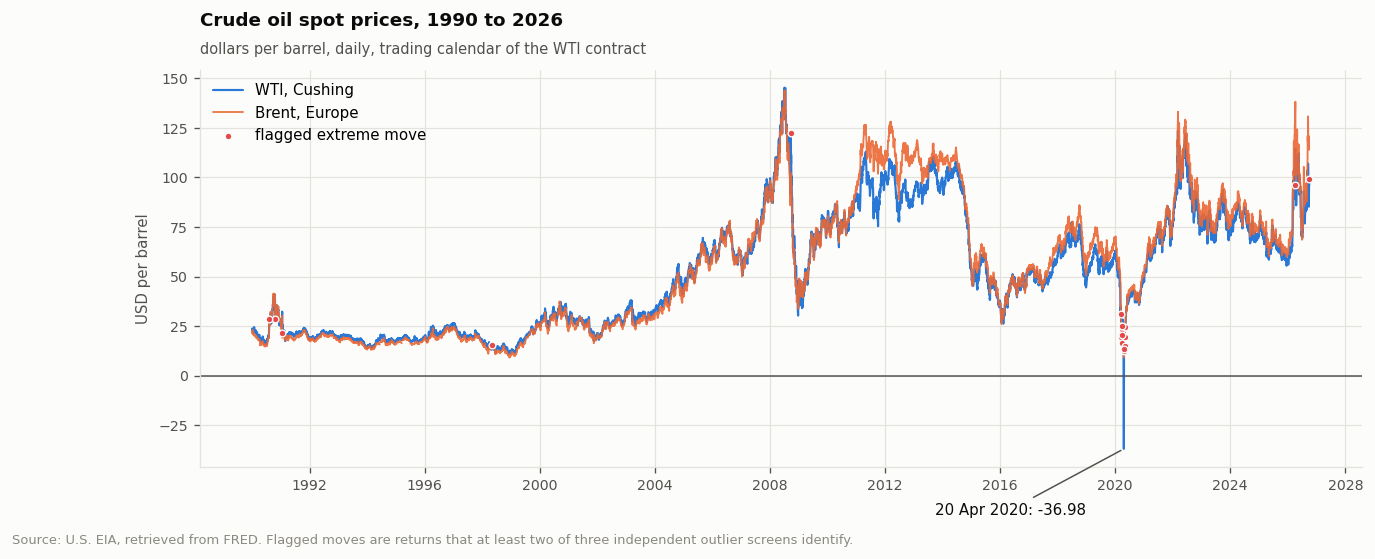

In [22]:
fg.fig_price_history(daily, rep["extremes_wti_d"]); plt.show()

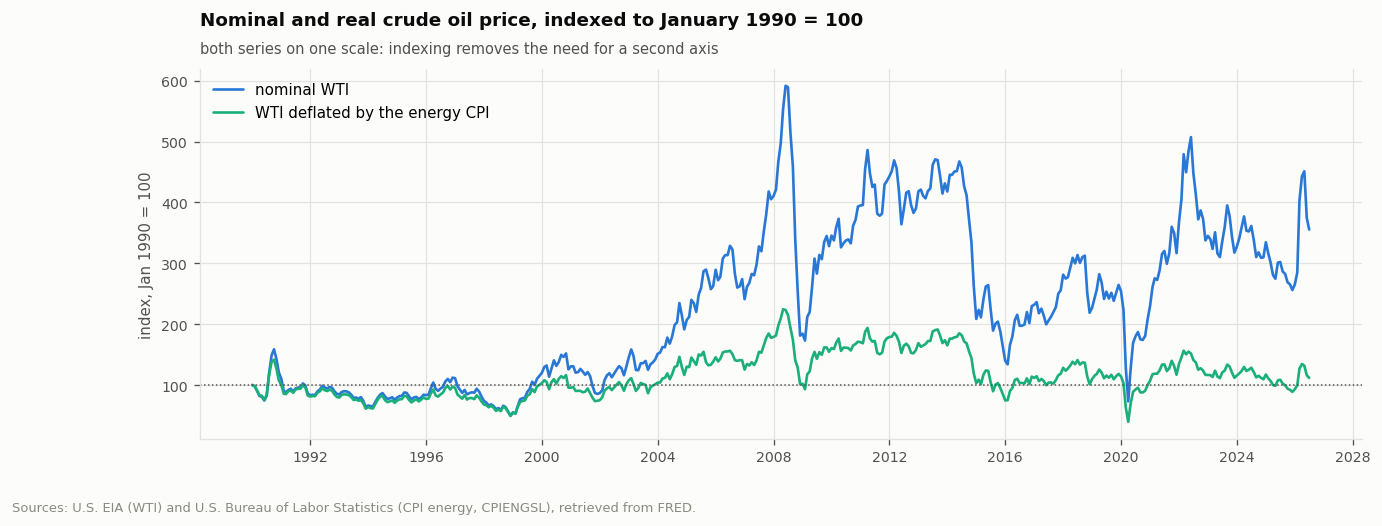

In [23]:
fg.fig_real_vs_nominal(monthly); plt.show()

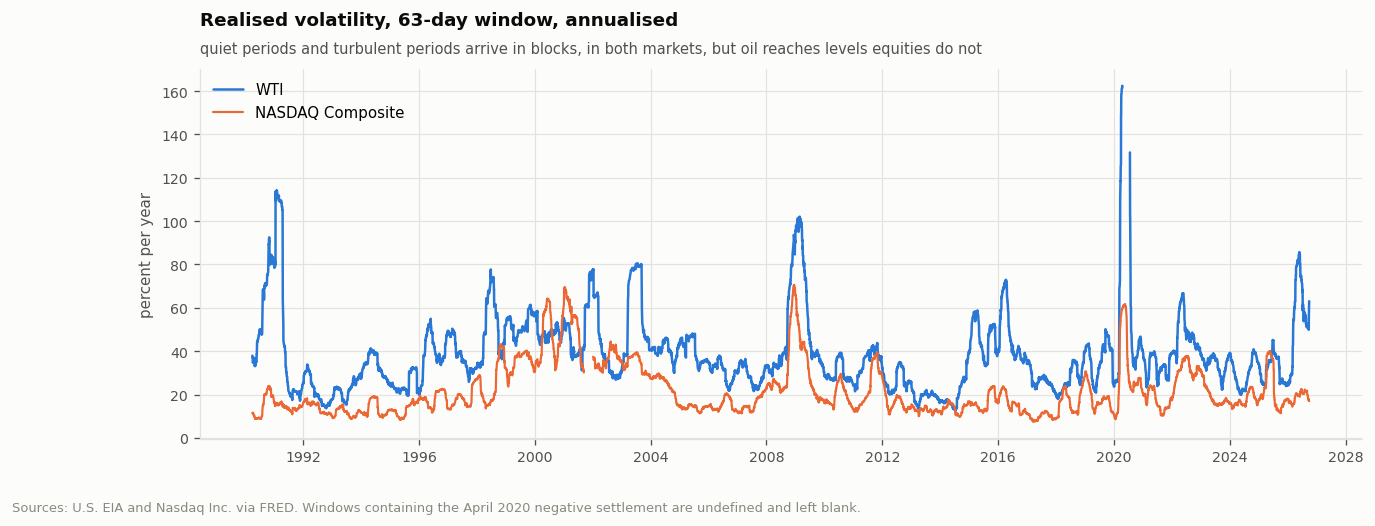

In [24]:
fg.fig_volatility(daily); plt.show()

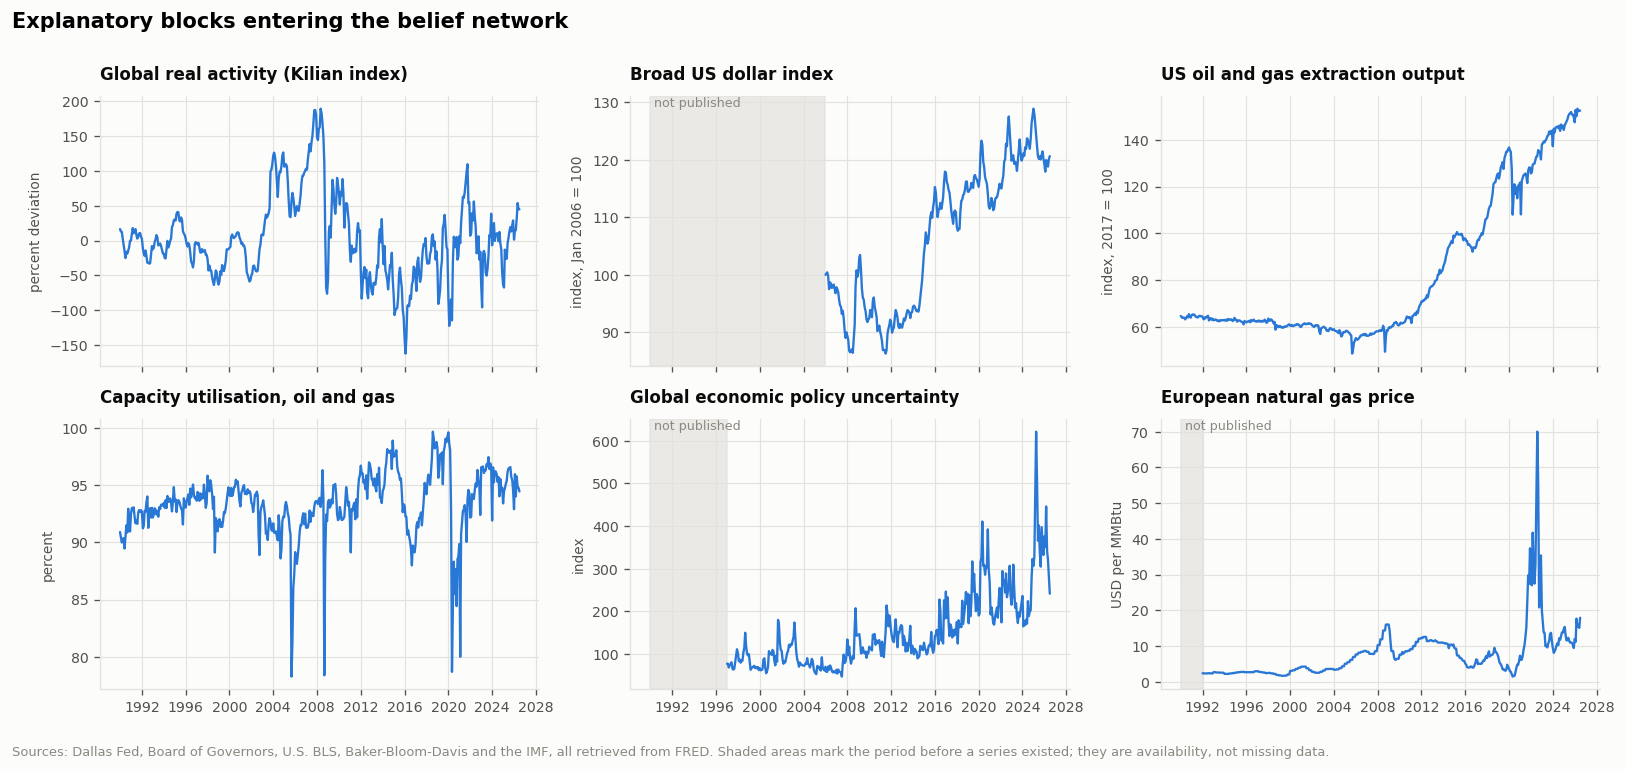

In [25]:
fg.fig_driver_panel(monthly); plt.show()

## 7a. Student A: distributional plots

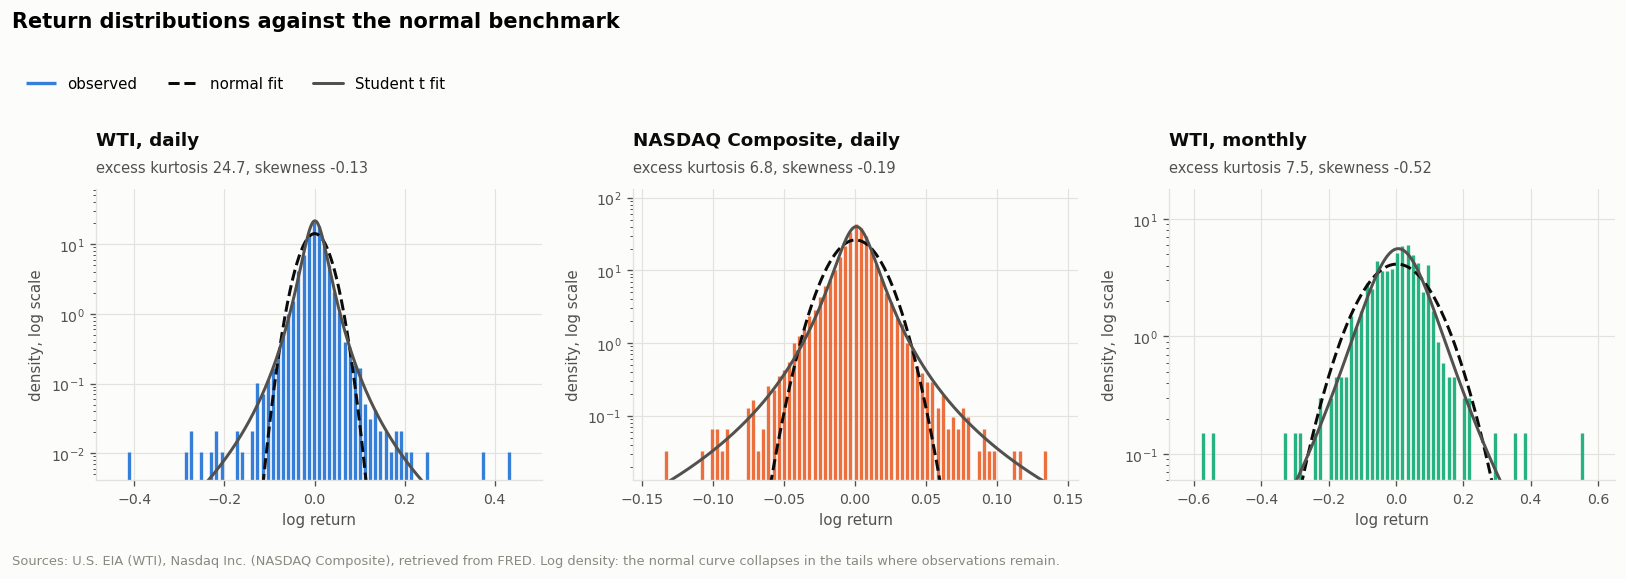

In [26]:
fg.fig_return_distributions(daily, monthly); plt.show()

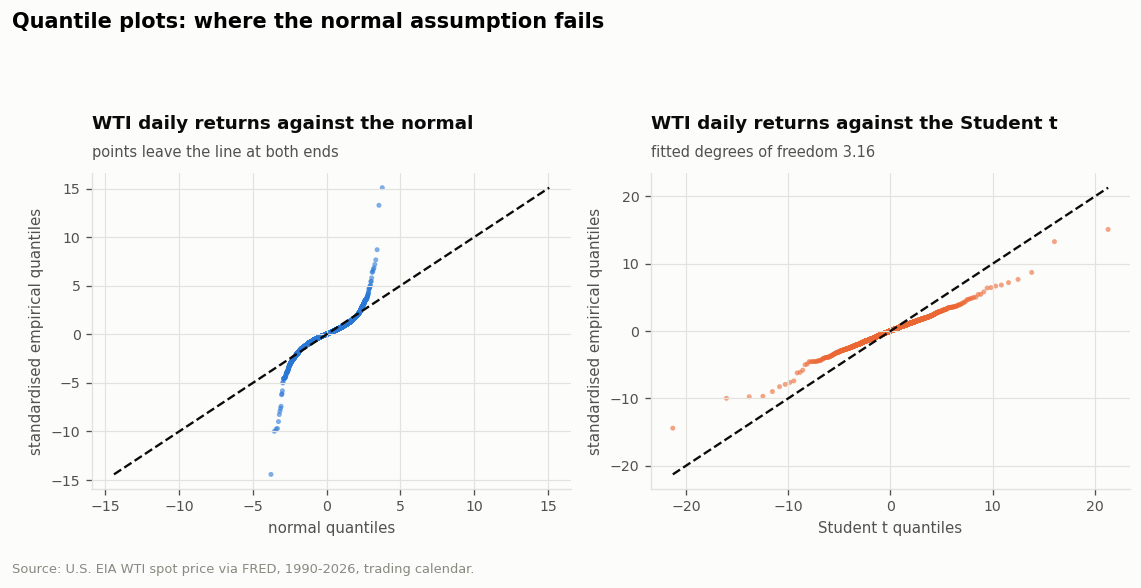

In [27]:
fg.fig_qq(daily); plt.show()

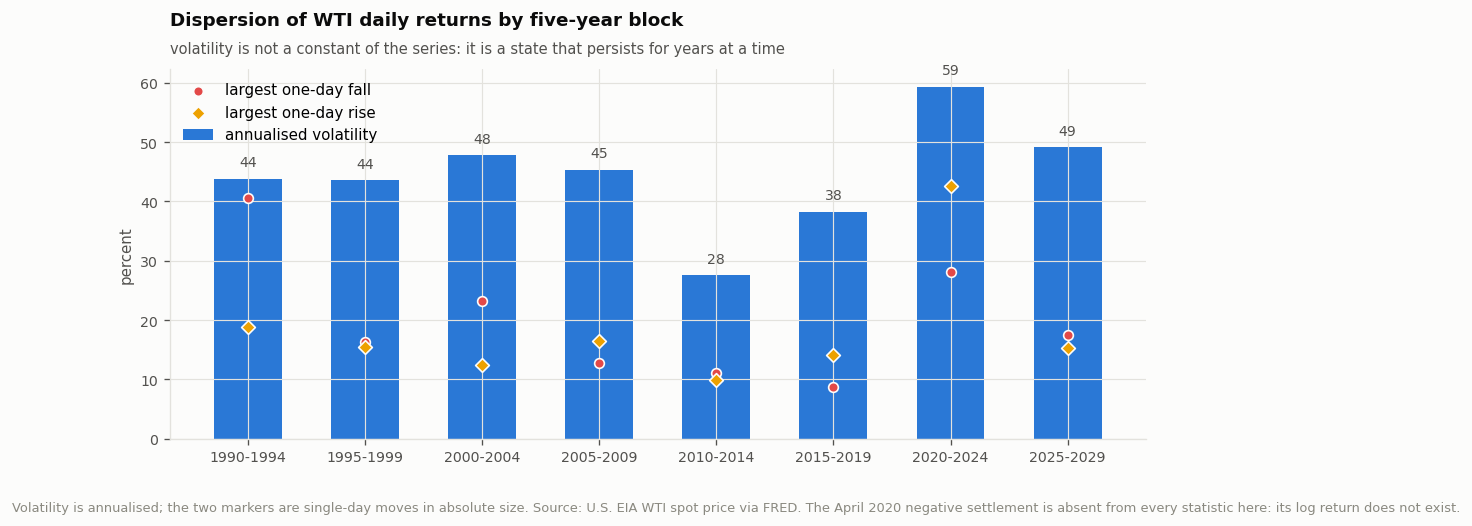

In [28]:
fg.fig_decade_boxplot(daily); plt.show()

## 7c. Student C: multivariate plots

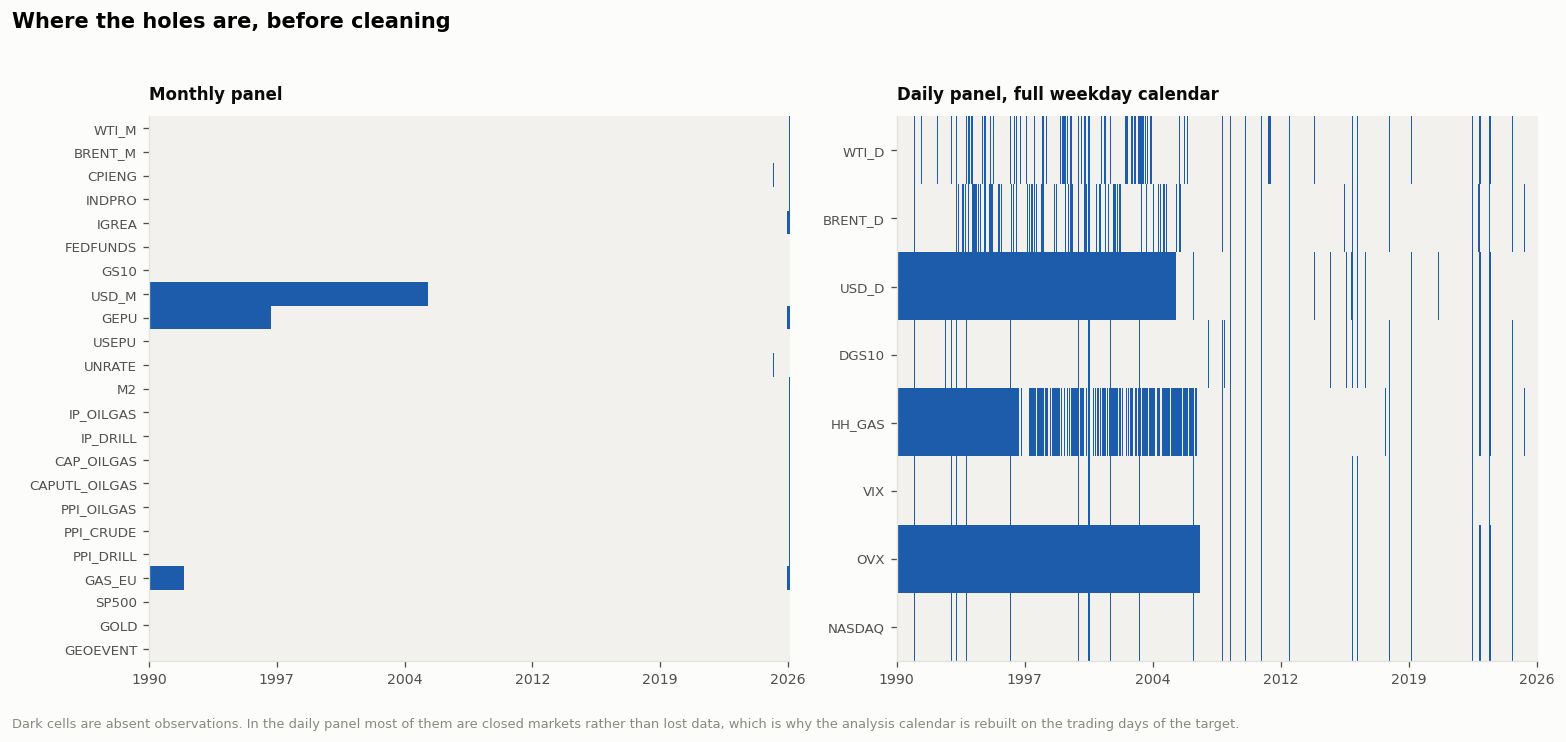

In [29]:
fg.fig_missingness(out["monthly_raw"], out["daily_raw"]); plt.show()

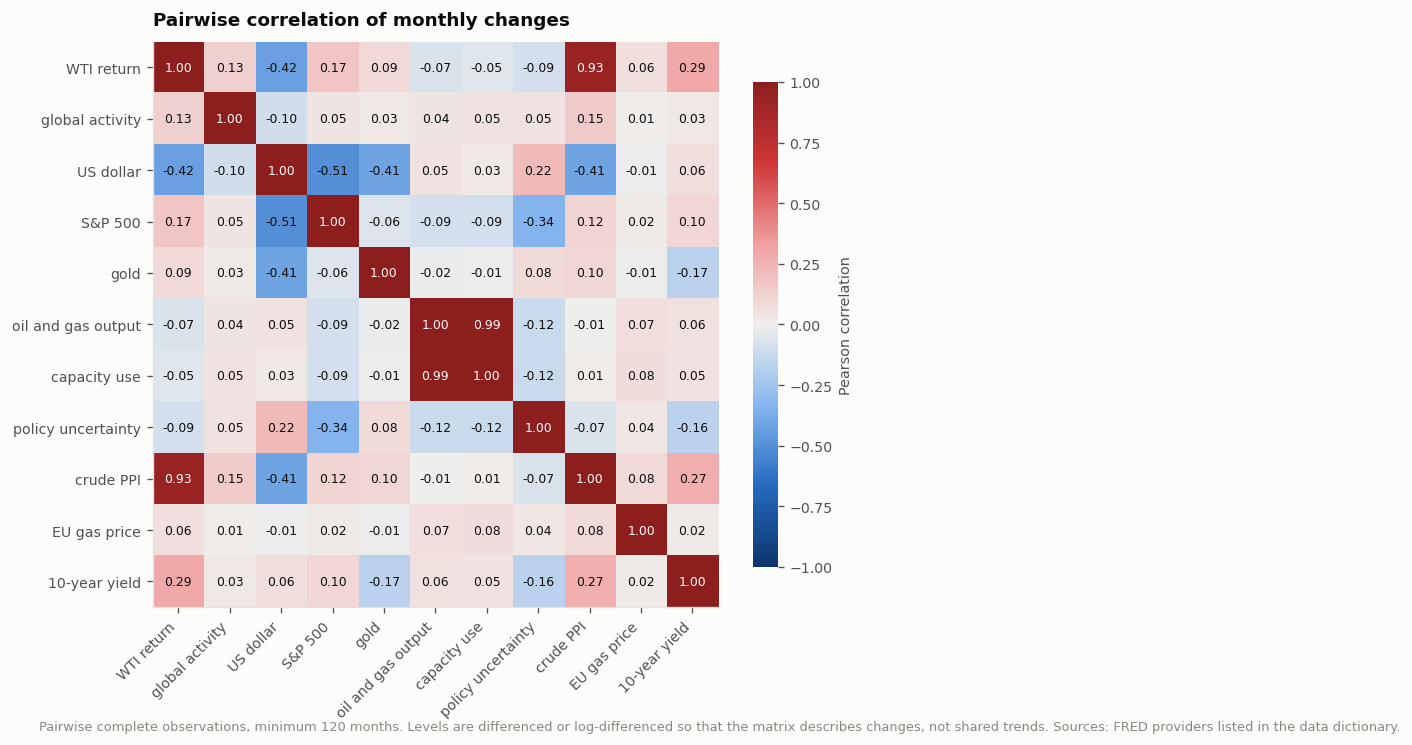

In [30]:
fg.fig_correlation_heatmap(monthly); plt.show()

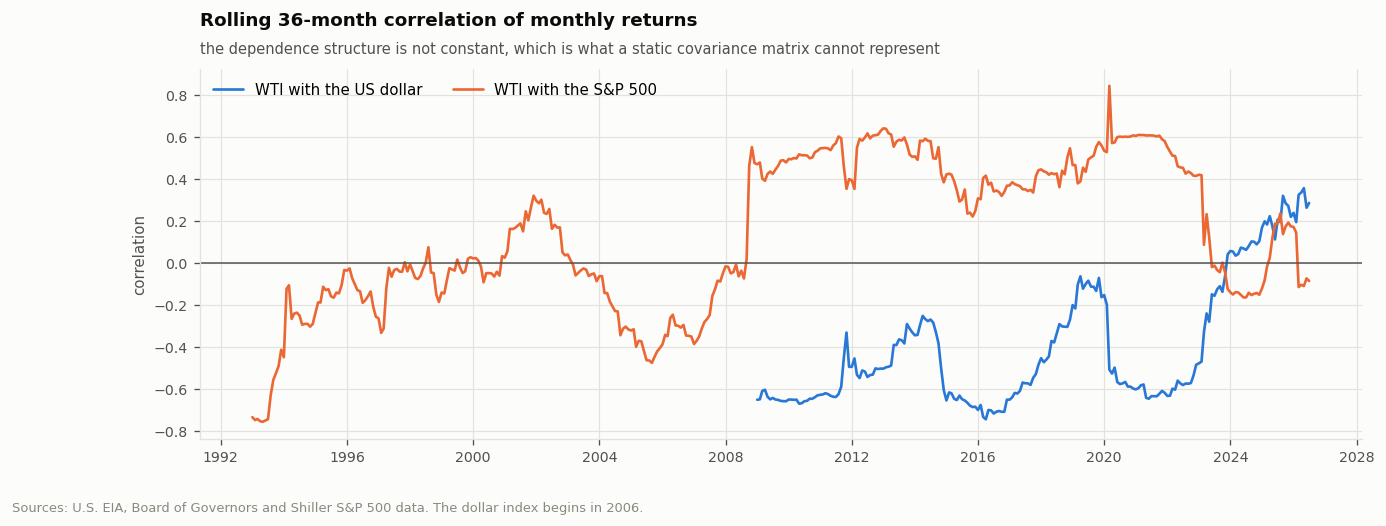

In [31]:
fg.fig_rolling_correlation(monthly); plt.show()

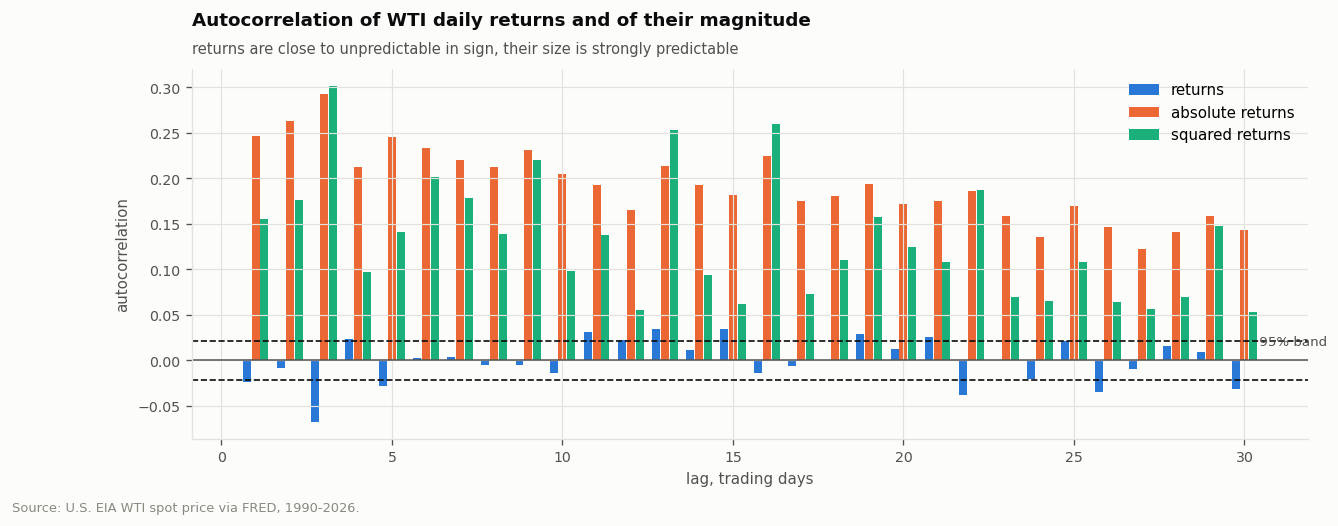

In [32]:
fg.fig_acf(daily); plt.show()

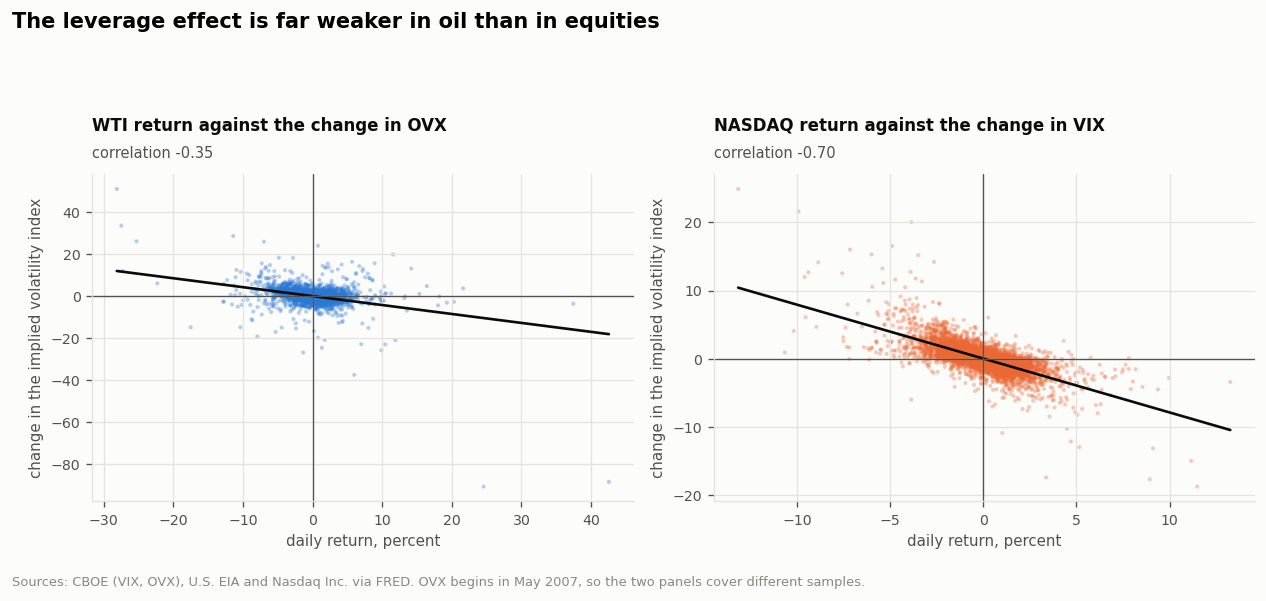

In [33]:
fg.fig_leverage(daily); plt.show()

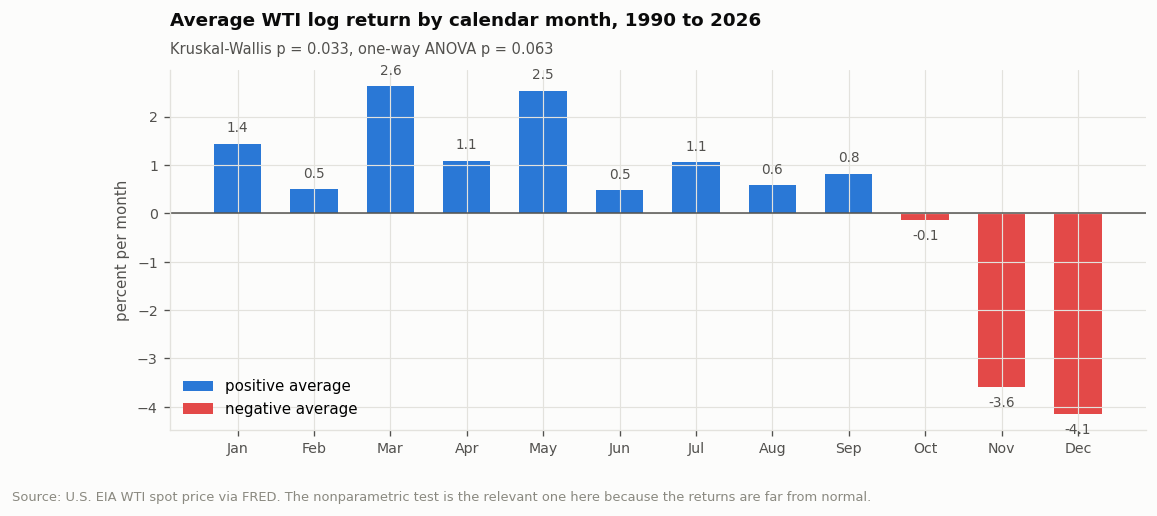

In [34]:
fg.fig_seasonality(monthly); plt.show()

# Step 8. The stylized facts

The comparison throughout is against the NASDAQ Composite over the identical sample, which
holds the period, the calendar and the estimation method fixed so that what remains is a
difference between the assets.

## 8a. What makes oil prices look different from other asset prices?

In [35]:
rows = []
for name, r, lvl in [("WTI", daily["WTI_RET"], daily["WTI_D"]),
                     ("NASDAQ Composite", daily["NASDAQ_RET"], daily["NASDAQ"])]:
    rr = r.dropna()
    rows.append(dict(Asset=name, observations=len(rr),
                     annualised_vol=rr.std() * np.sqrt(252),
                     excess_kurtosis=rr.kurtosis(), skewness=rr.skew(),
                     worst_day=rr.min(), best_day=rr.max(),
                     can_go_negative=bool((lvl.dropna() <= 0).any())))
pd.DataFrame(rows).set_index("Asset").T

Asset,WTI,NASDAQ Composite
observations,8547,8544
annualised_vol,0.4479,0.2416
excess_kurtosis,24.7430,6.8165
skewness,-0.1324,-0.1893
worst_day,-0.4064,-0.1315
best_day,0.4258,0.1325
can_go_negative,True,False


In [36]:
# median realised volatility and the persistence of the volatility state
reg_o = an.regime_summary(daily["WTI_RET"])
reg_e = an.regime_summary(daily["NASDAQ_RET"])
print(f"WTI    median annualised vol {reg_o.attrs['median_annualised_vol']:.1%}, "
      f"P(stay high) {reg_o.loc['high vol','to high vol']:.3f}, "
      f"expected episode {1/(1-reg_o.loc['high vol','to high vol']):.0f} trading days")
print(f"NASDAQ median annualised vol {reg_e.attrs['median_annualised_vol']:.1%}, "
      f"P(stay high) {reg_e.loc['high vol','to high vol']:.3f}, "
      f"expected episode {1/(1-reg_e.loc['high vol','to high vol']):.0f} trading days")
display(reg_o.round(4))

WTI    median annualised vol 34.9%, P(stay high) 0.985, expected episode 68 trading days
NASDAQ median annualised vol 17.1%, P(stay high) 0.990, expected episode 96 trading days


,to low vol,to high vol
low vol,0.9854,0.0146
high vol,0.0146,0.9854


In [37]:
# the leverage effect, oil against equities
lev = pd.DataFrame({"WTI vs OVX": an.volatility_asymmetry(daily["WTI_RET"], daily["OVX"]),
                    "NASDAQ vs VIX": an.volatility_asymmetry(daily["NASDAQ_RET"], daily["VIX"])})
lev.round(4)

,WTI vs OVX,NASDAQ vs VIX
n,"4,808.0000","8,544.0000"
corr_return_vs_dvol,-0.3523,-0.6991
mean_dvol_after_up,-0.5722,-0.7182
mean_dvol_after_down,0.5293,0.8728
asymmetry,-0.0429,0.1546


In [38]:
seas = an.monthly_seasonality(monthly["WTI_RET"])
print(f"one-way ANOVA   F = {seas.attrs['anova_F']:.3f}, p = {seas.attrs['anova_p']:.4f}")
print(f"Kruskal-Wallis  H = {seas.attrs['kruskal_H']:.3f}, p = {seas.attrs['kruskal_p']:.4f}")
(seas[["mean", "std"]] * 100).round(2).rename(columns={"mean": "mean %", "std": "std %"})

one-way ANOVA   F = 1.737, p = 0.0631
Kruskal-Wallis  H = 21.020, p = 0.0332


,mean %,std %
Jan,1.4400,7.8700
Feb,0.5100,6.7100
Mar,2.6300,13.9000
Apr,1.0900,12.2600
May,2.5400,11.3100
Jun,0.4800,9.0900
Jul,1.0600,6.4500
Aug,0.5800,9.1700
Sep,0.8200,7.4300
Oct,-0.1300,8.4100


In [39]:
an.stationarity({"WTI level (monthly)": monthly["WTI_M"],
                 "WTI real (monthly)": monthly["WTI_REAL"],
                 "WTI log return (monthly)": monthly["WTI_RET"],
                 "WTI level (daily)": daily["WTI_D"].dropna(),
                 "WTI log return (daily)": daily["WTI_RET"],
                 "Brent-WTI spread": monthly["BRENT_WTI_SPREAD"]}).round(4)

/content/src/analysis.py:114: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p = kpss(s, regression="c", nlags="auto")[:2]
/content/src/analysis.py:114: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p = kpss(s, regression="c", nlags="auto")[:2]
/content/src/analysis.py:114: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p = kpss(s, regression="c", nlags="auto")[:2]
/content/src/analysis.py:114: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p = kp

,n,ADF_stat,ADF_p,KPSS_stat,KPSS_p,verdict
Series,,,,,,
WTI level (monthly),439,-2.6752,0.0784,2.0858,0.0100,unit root / inconclusive
WTI real (monthly),439,-3.2986,0.0149,1.1696,0.0100,unit root / inconclusive
WTI log return (monthly),438,-12.6679,0.0000,0.0317,0.1000,stationary
WTI level (daily),8550,-2.3382,0.1599,7.8410,0.0100,unit root / inconclusive
WTI log return (daily),8547,-15.1162,0.0000,0.0391,0.1000,stationary
Brent-WTI spread,439,-2.8062,0.0574,1.3962,0.0100,unit root / inconclusive


**Answer.** Six differences, each measured above.

1. **The price can be negative, and the standard toolkit breaks when it is.** Crude is a
   physical commodity with a binding storage constraint. An equity price is bounded below
   by zero because limited liability makes it so. Log returns are undefined at the
   crossing and maximum drawdown becomes meaningless.
2. **The tails are far heavier.** Excess kurtosis 24.7 against 6.8 over the same days, a
   ratio of about three and a half to one. The worst and best WTI days are -40.6 and
   +42.6 percent, against -13.2 and +13.3 for the equity index.
3. **Volatility lives at a different level.** Median annualised realised volatility of
   34.9 percent against 17.1 percent, sustained over three and a half decades.
4. **Volatility clusters in both, in blocks of comparable length.** The probability of
   remaining in the high-volatility state is 0.985 daily for WTI, an expected episode of
   about 68 trading days.
5. **The leverage effect is weak and tilted the other way.** The NASDAQ return correlates
   -0.70 with the change in the VIX, with an asymmetry of +0.155 in favour of down days.
   WTI against the OVX gives only -0.35 and an asymmetry of -0.043, slightly in favour of
   *up* days. A rising oil price signals scarcity, and scarcity is itself a source of
   uncertainty, so an upward shock carries nearly as much volatility information as a
   downward one.
6. **Seasonality is present but weak.** Average returns run from +2.6 percent in March to
   -4.1 percent in December. The ANOVA does not reject at five percent (p = 0.063) while
   the Kruskal-Wallis test, which assumes no normality and is the appropriate test here,
   does (p = 0.033). The effect is real but small against a monthly standard deviation of
   roughly nine percent.

The level is non-stationary and the return is stationary, at both frequencies. Deflating
by the energy CPI moves the level toward stationarity, consistent with slow mean reversion
toward a real marginal cost, but the two tests still disagree and we claim no more.

## 8b. What type of distributions do the oil returns have?

In [40]:
profile = an.distribution_profile({"WTI daily": daily["WTI_RET"],
                                   "Brent daily": daily["BRENT_RET"],
                                   "NASDAQ daily": daily["NASDAQ_RET"],
                                   "WTI monthly": monthly["WTI_RET"]})
profile.T.round(4)

Series,WTI daily,Brent daily,NASDAQ daily,WTI monthly
n,"8,547.0000","8,394.0000","8,544.0000",438.0000
mean,0.0003,0.0002,0.0005,0.0029
std,0.0282,0.0267,0.0152,0.0967
skewness,-0.1324,-1.7453,-0.1893,-0.5250
excess_kurtosis,24.7279,60.1600,6.8118,7.5442
JB_stat,"217,783.8331","1,270,084.9396","16,569.5100","1,058.8222"
JB_p,0.0000,0.0000,0.0000,0.0000
KS_vs_normal_p,0.0000,0.0000,0.0000,0.0199
student_t_df,3.1576,2.9440,2.6885,4.0969
q01,-0.0755,-0.0689,-0.0430,-0.2726


In [41]:
pd.DataFrame({k: an.tail_comparison(v) for k, v in
              {"WTI daily": daily["WTI_RET"], "Brent daily": daily["BRENT_RET"],
               "NASDAQ daily": daily["NASDAQ_RET"],
               "WTI monthly": monthly["WTI_RET"]}.items()}).T

,k,n,observed,expected_if_normal,ratio
WTI daily,4.0000,"8,547.0000",49.0000,0.5400,90.5000
Brent daily,4.0000,"8,394.0000",45.0000,0.5300,84.6000
NASDAQ daily,4.0000,"8,544.0000",52.0000,0.5400,96.1000
WTI monthly,4.0000,438.0000,3.0000,0.0300,108.1000


In [42]:
an.aggregational_gaussianity(daily["WTI_D"]).round(4)

,n,excess_kurtosis,skewness,std
horizon_days,,,,
1,8547,24.7279,-0.1324,0.0282
5,8543,14.5359,-0.2515,0.0605
21,8527,11.3575,-0.3672,0.1182
63,8485,6.4733,-0.7374,0.2134


**Answer.** Not normal, by any measure applied. Jarque-Bera rejects at every conventional
level in every series, and the Kolmogorov-Smirnov test against a fitted normal rejects
likewise.

The positive answer is the useful one: a **Student t with roughly three degrees of
freedom** fits the daily WTI return closely, and about four degrees of freedom fits the
monthly return. The quantile plot above shows the fitted t tracking the empirical
quantiles well into both tails where the normal has already failed. Three degrees of
freedom is a strong statement: the fourth moment of such a distribution does not exist, so
the sample kurtosis of 24.7 is not an estimate of a population quantity, and any risk
measure resting on a variance-covariance assumption is estimating something the data may
not have.

Forty-nine WTI observations lie beyond four standard deviations where a Gaussian predicts
half an observation, a ratio of about ninety to one.

**Aggregational Gaussianity holds**, which is the standard check that the fat tails are a
property of the sampling frequency rather than of a corrupted series: excess kurtosis falls
monotonically from 24.7 at one day to 14.5 at five days, 11.4 at one month and 6.5 at one
quarter, while skewness becomes steadily more negative. The distribution approaches
normality as the horizon lengthens, and never arrives.

Brent is the heavier-tailed benchmark, with excess kurtosis 60 and skewness -1.75, both
driven by 21 April 2020 when it fell from 17.36 to 9.12 dollars. A single observation in
8,394 moves the skewness by more than one and a half units, which is itself a finding:
sample moments of oil returns are not stable statistics.

## 8c. What type of autocorrelation do the oil returns have?

In [43]:
print("WTI daily"); display(an.autocorrelation_profile(daily["WTI_RET"]).round(4))
print("NASDAQ daily"); display(an.autocorrelation_profile(daily["NASDAQ_RET"]).round(4))

WTI daily


,acf_lag1,acf_lag5,acf_lag10,acf_lag22,LB_p_lag1,LB_p_lag5,LB_p_lag10,LB_p_lag22
returns,-0.0237,-0.0285,-0.0135,-0.0385,0.0285,0.0000,0.0000,0.0000
absolute returns,0.2465,0.2454,0.2048,0.1862,0.0000,0.0000,0.0000,0.0000
squared returns,0.1554,0.1407,0.0984,0.1869,0.0000,0.0000,0.0000,0.0000


NASDAQ daily


,acf_lag1,acf_lag5,acf_lag10,acf_lag22,LB_p_lag1,LB_p_lag5,LB_p_lag10,LB_p_lag22
returns,-0.0395,0.0042,-0.0197,0.0067,0.0003,0.0021,0.0000,0.0000
absolute returns,0.2896,0.3182,0.2980,0.2273,0.0000,0.0000,0.0000,0.0000
squared returns,0.2709,0.2452,0.2497,0.1417,0.0000,0.0000,0.0000,0.0000


In [44]:
pd.DataFrame({"WTI": an.arch_test(daily["WTI_RET"]),
              "NASDAQ": an.arch_test(daily["NASDAQ_RET"])}).round(4)

,WTI,NASDAQ
lags,12.0000,12.0000
LM_stat,"1,380.7158","1,761.5748"
LM_p,0.0000,0.0000
F_stat,137.0561,184.7109
F_p,0.0000,0.0000


**Answer.** Two parts, and conflating them is the usual error.

**The sign of the return is close to unpredictable.** First-order autocorrelation is
-0.024, at lag five -0.029, at lag ten -0.014. Ljung-Box does reject at every horizon, but
with 8,547 observations it has power against departures far too small to trade, and the
NASDAQ behaves identically at -0.040. Weak-form efficiency is not seriously in question
for either series.

**The magnitude of the return is strongly and persistently predictable.** The
autocorrelation of absolute returns is 0.247 at lag one, 0.245 at lag five, 0.205 at lag
ten and still 0.186 at lag twenty-two, a full trading month. Squared returns follow the
same profile. All lie far outside the 95 percent band, and the ARCH Lagrange multiplier
test at twelve lags returns a statistic of 1,380.7 with a p-value indistinguishable from
zero.

This is volatility clustering, and it is what the hidden Markov layer of Alvi's design
exists to capture. Volatility in crude is not a parameter; it is a state that persists for
a season and then switches, which is what a Markov chain represents and a constant-variance
model cannot.

## 8d. What other stylized facts can be said about oil prices?

In [45]:
mm = pd.DataFrame({
    "WTI return": monthly["WTI_RET"],
    "global activity": monthly["IGREA"].diff(),
    "US dollar": np.log(monthly["USD_M"]).diff(),
    "S&P 500": np.log(monthly["SP500"]).diff(),
    "gold": np.log(monthly["GOLD"]).diff(),
    "oil and gas output": np.log(monthly["IP_OILGAS"]).diff(),
    "capacity use": monthly["CAPUTL_OILGAS"].diff(),
    "policy uncertainty": np.log(monthly["GEPU"]).diff(),
    "crude PPI": np.log(monthly["PPI_CRUDE"]).diff(),
    "10-year yield": monthly["GS10"].diff()})
corr = mm.corr(min_periods=120)
corr["WTI return"].drop("WTI return").sort_values().to_frame("correlation with WTI return").round(4)

,correlation with WTI return
US dollar,-0.4224
policy uncertainty,-0.0871
oil and gas output,-0.0681
capacity use,-0.0510
gold,0.0920
global activity,0.1291
S&P 500,0.1723
10-year yield,0.2920
crude PPI,0.9302


In [46]:
# near-deterministic pairs, which a structure-learning algorithm would waste edges on
pairs = [(a, b, round(corr.loc[a, b], 4))
         for i, a in enumerate(corr.columns) for b in corr.columns[i+1:]
         if abs(corr.loc[a, b]) > 0.85]
pd.DataFrame(pairs, columns=["variable A", "variable B", "correlation"])

,variable A,variable B,correlation
0,WTI return,crude PPI,0.9302
1,oil and gas output,capacity use,0.9870


In [47]:
# direction of the relationship between global activity and the oil price
ll = an.lead_lag(monthly["IGREA"].diff(), monthly["WTI_RET"], 6).round(4)
ll.T

lag,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6
corr,-0.0720,-0.0244,-0.0929,-0.0842,0.1052,0.2132,0.1291,0.1404,0.0812,0.0580,-0.0183,0.0019,-0.0137


**Answer.** Four further facts, each with a direct consequence for GWP2.

**The dollar is the strongest single macroeconomic correlate.** The correlation between
the monthly WTI return and the monthly change in the broad dollar index is **-0.422**, the
largest absolute value in the matrix outside of mechanical identities. Crude is invoiced in
dollars, so a stronger dollar raises the price in every other currency and compresses
demand. At daily frequency the same correlation is -0.224.

**Causal direction is genuinely ambiguous, which is the argument for structure learning.**
The contemporaneous correlation between the change in the Kilian activity index and the WTI
return is 0.129. Lagging activity by one month gives 0.140, so activity appears to lead the
price. Leading it by one month gives 0.213, so the price appears to lead activity more
strongly than the reverse. Both readings come from the same data. No amount of staring at
the correlation matrix settles the orientation; deciding it requires conditional
independence testing or scored search over graphs, which is exactly what GWP2 will do.

**Two pairs are near-deterministically related and must be handled before any graph is
learnt.** Extraction output and capacity utilisation correlate at **0.987**, unsurprisingly
since utilisation is output divided by capacity. The crude producer price index correlates
at **0.930** with the WTI return, because it is a measurement of the same quantity rather
than a driver of it. A structure-learning algorithm presented with either pair will connect
it with near certainty and will spend its edge budget on a tautology.

**Dependence itself is time-varying.** The rolling 36-month correlation between WTI and the
S&P 500 moves from roughly -0.7 in the early 1990s to +0.6 after 2009 and back toward zero
after 2023. A single covariance matrix estimated over the full sample would describe none
of these regimes, which argues both for the regime layer and against any risk aggregation
treating cross-asset correlation as a constant.

# Step 9. Modelling foundations

The written two-page summaries are in Section 6 of the PDF report: probabilistic graphical
models and the belief-network versus Markov-network distinction (Student A), parameter
learning versus structure learning (Student B), and Markov chains and Markov blankets
(Student C). The cell below estimates the two-state volatility Markov chain referred to
there, as the empirical counterpart of the hidden Markov layer that Alvi fits before
discretisation.

In [48]:
chain = an.regime_summary(daily["WTI_RET"], window=63)
print(f"state defined by the trailing 63-day annualised volatility against its median "
      f"({chain.attrs['median_annualised_vol']:.1%})")
display(chain.round(4))
p_hh = chain.loc["high vol", "to high vol"]
p_ll = chain.loc["low vol", "to low vol"]
print(f"expected time in the high-volatility state: {1/(1-p_hh):.0f} trading days")
print(f"expected time in the low-volatility state : {1/(1-p_ll):.0f} trading days")
print(f"stationary share of high-volatility days  : "
      f"{(1-p_ll)/((1-p_ll)+(1-p_hh)):.1%}")

state defined by the trailing 63-day annualised volatility against its median (34.9%)


,to low vol,to high vol
low vol,0.9854,0.0146
high vol,0.0146,0.9854


expected time in the high-volatility state: 68 trading days
expected time in the low-volatility state : 68 trading days
stationary share of high-volatility days  : 50.0%


# Step 10. Our pseudocode for Algorithm 1, Inferred Causality

Our own reconstruction. It expands the Markov blanket step into the Grow-Shrink subroutine,
makes the separating sets explicit because the orientation phase cannot proceed without
them, and adds the propagation rules that complete the graph once the v-structures are
oriented. The full version with commentary is in Section 7 of the report.

```
ALGORITHM  InferredCausality(D, alpha)

INPUT   D      dataset over V = {X1,...,Xm}, discrete after regime discretisation
        alpha  significance level of the conditional independence test
OUTPUT  G      completed partially directed acyclic graph (CPDAG) over V

PHASE 1  learn a Markov blanket for every variable
1   for each X in V:  B(X) <- GrowShrink(X, V, D, alpha)
2   for each ordered pair (X, Y) with Y in B(X):
3       if X not in B(Y): remove Y from B(X)     # symmetry filters false positives

PHASE 2  learn the skeleton inside each blanket
4   E <- {} ;  Sepset <- {}
5   for each unordered pair {X, Y} with Y in B(X):
6       smaller <- the smaller of B(X)\{Y} and B(Y)\{X}
7       for d = 0 to |smaller|, for each subset S of smaller with |S| = d:
8           if Indep(X, Y | S):  Sepset[{X,Y}] <- S ;  mark separated ;  break
9       if not separated:  add the undirected edge X - Y to E

PHASE 3a  orient the v-structures
10  for each triple (X, Z, Y) with X-Z, Z-Y in E and X-Y not in E:
11      if Z not in Sepset[{X,Y}]:  orient X -> Z <- Y

PHASE 3b  propagate the forced orientations (Meek's rules), until nothing changes
12      R1  X -> Z, Z - Y, X not adjacent to Y                  =>  Z -> Y
13      R2  X -> Z -> Y, X - Y                                  =>  X -> Y
14      R3  X-Z, X-U, X-Y, Z -> Y, U -> Y, Z not adj. to U      =>  X -> Y
15      R4  X-Z, X-U, Z -> U, U -> Y, X-Y, Z not adj. to Y      =>  X -> Y
16  return G

SUBROUTINE  GrowShrink(X, V, D, alpha)
S1  B <- {}
S2  GROW:    repeat  for each Y in V\({X} u B): if not Indep(X,Y|B): B <- B u {Y}
             until B stops changing
S3  SHRINK:  for each Y in B: if Indep(X, Y | B\{Y}): B <- B\{Y}
S4  return B
```

**Reading the output.** The returned graph is an equivalence class, not a single model. An
edge still undirected after Phase 3b is one whose orientation the data cannot determine,
because both orientations imply the same conditional independencies. That is a property of
observational data, not a failure of the algorithm, and it is why Alvi's specification says
the output is a *completed, partially directed* acyclic graph.

**Three practical notes for GWP2.** With 439 monthly observations and three regimes per
variable, a test conditioning on three or more variables reads a contingency table whose
cells are often empty, so a maximum conditioning-set size must be imposed and recorded. The
order in which pairs are examined changes the result when tests disagree, so it must be
fixed and reported. And the near-deterministic pairs found in Step 8d will never be
separated by any conditioning set, so they must be resolved before the algorithm runs.

# Outputs written by this notebook

In [ ]:
import results as rs
R, _ = rs.collect()
print("results.json keys:", ", ".join(sorted(R)))
for f in sorted(os.listdir(os.path.join(os.path.dirname(SRC), "data_clean"))):
    print(" -", f)

results.json keys: acf_ndx, acf_wti, aggregation, arch_ndx, arch_wti, availability, cleaning, collinear_pairs, correlation_with_wti, daily_corr, distribution, drawdown, lead_lag_igrea, leverage_equity, leverage_oil, negative_price, regimes, sample, seasonality, stationarity, tails
 - daily_sterilised.csv
 - elimination_log.csv
 - monthly_sterilised.csv
 - results.json


In [ ]:
import json, os
from google.colab import _message, files

NOM = "GWP1_Oil_Price_PGM_Code"

nb = _message.blocking_request("get_ipynb", request="", timeout_sec=300)["ipynb"]
with open(f"{NOM}.ipynb", "w", encoding="utf-8") as f:
    json.dump(nb, f)

!jupyter nbconvert --to html --embed-images "{NOM}.ipynb"

print("taille HTML :", round(os.path.getsize(f"{NOM}.html")/1024/1024, 1), "Mo")
files.download(f"{NOM}.html")
files.download(f"{NOM}.ipynb")